# Estado del arte: modelos de LGD y EAD frente a la evidencia comparada

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 03, 05 y 06 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar lo que encontraron los estudios comparados de pérdida dado el incumplimiento y de exposición al incumplimiento, con sus fuentes, y decir cuáles de las familias de modelos que comparan implementa Contraste y cuáles no;
- comprobar, en las seis cohortes de incumplimiento de C08, las afirmaciones sobre el R cuadrado, los modelos no lineales frente a los lineales, el logit fraccional frente a MCO y la sensibilidad del modelo beta a su ajuste de extremos;
- comprobar, en los seis niveles de aceleración de C09, cómo se compara un modelo de EAD directo con los modelos de factor y con el modelo de cambio de utilización, según el backtest del propio motor;
- decir lo que estas comprobaciones no muestran, para que un resultado sobre un proxy de castigos y sobre un generador no se lea como un resultado sobre un banco.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation import lgd_ead as tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Doce artefactos versionados: las seis variantes por cohorte de incumplimiento del caso C08 (`dc-2003-06.json` a `dc-2020-23.json`), donde la LGD es un proxy de castigos sobre los préstamos a pequeñas empresas SBA 7(a) (cuaderno 01), y las seis variantes por nivel de aceleración del caso C09 (`level-0.json` a `level-5.json`), un generador de líneas de crédito rotativas con un CCF conocido (cuaderno 02). Dos salvedades enmarcan todo lo que sigue. El objetivo de C08 es un proxy con un sesgo declarado y no una LGD de recuperación, y las líneas de C09 son sintéticas, así que las comparaciones tratan de los modelos sobre estos datos y no de ningún prestamista. Y los artefactos fueron horneados con un motor anterior al instalado; la celda siguiente imprime las versiones.

In [2]:
# Cargar las seis variantes por cohorte de C08 y los seis niveles de C09 e imprimir las versiones que los hornearon
ROOT = Path("../../..").resolve()
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
c08 = {c: json.loads((ROOT / "data" / "derived" / "C08" / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
c09 = [json.loads((ROOT / "data" / "derived" / "C09" / f"level-{i}.json").read_text(encoding="utf-8")) for i in range(6)]
print("C08:", sorted({v["provenance"]["riskvalidation_version"] for v in c08.values()}), "| C09:", sorted({v["provenance"]["riskvalidation_version"] for v in c09}), "| instalado:", rv.__version__)
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluado"}
RUNG = {"L1-ols": "MCO", "L2-fractional-logit": "logit fraccional", "L3-beta": "beta", "L4-hurdle": "hurdle", "L5-gradient-boosted": "árboles con boosting", "L6-tobit": "Tobit"}

C08: ['0.6.0'] | C09: ['0.6.0'] | instalado: 0.8.1


## Método

### Paso 1: las cantidades de LGD a comparar

La comparación necesita, para cada cohorte y peldaño, cuatro números que presentó el cuaderno 03: el R cuadrado, el RMSE, la correlación de rangos de Spearman y la brecha de calibración (proxy realizado medio menos predicho medio). Con ellos la celda deriva, cohorte por cohorte, las cinco cantidades sobre las que tratan las afirmaciones de la sección siguiente:

1. el rango del R cuadrado entre los peldaños;
2. la ganancia de R cuadrado de los árboles con boosting sobre el logit fraccional (no lineal frente a lineal), y el peldaño con la mayor correlación de Spearman;
3. la diferencia de R cuadrado y de RMSE entre el logit fraccional y MCO;
4. la correlación de rangos, entre los peldaños de la cohorte, del R cuadrado con la brecha de calibración absoluta (negativa significa que un mayor R cuadrado va con una menor brecha);
5. el rango de la predicción media del peldaño beta sobre los tres ajustes de extremos de `endpoint_sensitivity`, frente a la diferencia entre las brechas de calibración del peldaño beta y del logit fraccional.

Un peldaño que no corrió en una cohorte (el hurdle, en tres cohortes, cuaderno 03) simplemente está ausente de su `rung_comparison`.

In [3]:
# Derivar las cinco cantidades para cada una de las seis cohortes desde las comparaciones de peldaños versionadas
rank = lambda x: np.argsort(np.argsort(x)) + 1.0
derived = {}
print(f"{'cohorte':8s} {'R cuadrado mín-máx':>22s} {'boosting - fraccional R cuad.':>30s} {'mejor Spearman':>28s} {'fraccional - MCO: R cuad., RMSE':>34s} {'corr. de rangos R cuad./|brecha|':>34s} {'beta: rango, |dif. de brechas|':>36s}")
for c in COHORTS:
    rc = {r["rung_id"]: r for r in c08[c]["outputs"]["rung_comparison"]}
    ids = list(rc)
    r2 = np.array([rc[k]["r2"] for k in ids])
    gap = np.array([abs(rc[k]["calibration_gap"]) for k in ids])
    best_sp = max(rc, key=lambda k: rc[k]["spearman"])
    means = [e["mean_predicted"]["value"] for e in c08[c]["outputs"]["endpoint_sensitivity"]]
    d = dict(
        r2_min=r2.min(), r2_max=r2.max(), gain=rc["L5-gradient-boosted"]["r2"] - rc["L2-fractional-logit"]["r2"], best_sp=best_sp,
        d_r2=rc["L2-fractional-logit"]["r2"] - rc["L1-ols"]["r2"], d_rmse=rc["L2-fractional-logit"]["rmse"] - rc["L1-ols"]["rmse"],
        rho=np.corrcoef(rank(r2), rank(gap))[0, 1],
        eps_range=max(means) - min(means), gap_diff=abs(rc["L3-beta"]["calibration_gap"] - rc["L2-fractional-logit"]["calibration_gap"]),
    )
    derived[c] = d
    print(f"{c:8s} {d['r2_min']:10.4f} -{d['r2_max']:8.4f} {d['gain']:30.4f} {RUNG[d['best_sp']]:>28s} {d['d_r2']:+16.4f} {d['d_rmse']:+16.4f} {d['rho']:34.3f} {d['eps_range']:16.4f} {d['gap_diff']:16.4f}")

cohorte      R cuadrado mín-máx  boosting - fraccional R cuad.               mejor Spearman    fraccional - MCO: R cuad., RMSE   corr. de rangos R cuad./|brecha|       beta: rango, |dif. de brechas|
2003-06      0.1990 -  0.2497                         0.0355         árboles con boosting          -0.0023          +0.0004                             -0.886           0.0057           0.0123
2007-08      0.1767 -  0.2435                         0.0422         árboles con boosting          +0.0029          -0.0005                             -0.771           0.0166           0.0145
2009-10      0.1083 -  0.1793                         0.0437         árboles con boosting          +0.0192          -0.0034                             -0.800           0.0234           0.0142
2011-13      0.0975 -  0.1632                         0.0526         árboles con boosting          +0.0016          -0.0003                              0.000           0.0147           0.0067
2014-19      0.1350 -  0.1925

### Paso 2: las cantidades de EAD a comparar

Para la exposición al incumplimiento, el backtest del motor (cuaderno 06) da, para cada modelo y nivel, la mayor brecha relativa absoluta por tramo de utilización, con un umbral verde en 0.10 y uno rojo en 0.25. Tres familias de modelos importan para la literatura: los modelos de factor (el CCF aplicado al monto no utilizado, aquí el diseño de horizonte fijo con piso y tope y sin tratamiento), el modelo de EAD directo (un logit fraccional de la EAD sobre el límite) y el modelo de cambio de utilización. La celda lee la métrica de backtest versionada de cada uno en cada nivel, con el número de líneas que el modelo directo recortó, y vuelve a correr `ead_backtest_by_band` del motor sobre los totales por tramo del nivel 4 para comprobar tres de las filas versionadas contra el motor instalado.

In [4]:
# Leer la métrica de backtest versionada de cuatro modelos de EAD en cada nivel y volver a correr el motor sobre los totales por tramo del nivel 4
FAMILIES = [("ccf-fixed-horizon-floor-cap", "factor, piso y tope"), ("ccf-fixed-horizon-none", "factor, sin tratamiento"), ("direct-ead", "EAD directo"), ("utilisation-change", "cambio de utilización")]
ead = {}
print(f"{'nivel':>5s} " + " ".join(f"{label:>34s}" for _, label in FAMILIES) + f" {'directo: líneas recortadas':>30s}")
for i, doc in enumerate(c09):
    rows = {t["model_id"]: t for t in doc["tests"] if t["test_id"] == "lgd_ead.ead_backtest_by_band"}
    clipped = next(m["n_clipped_above"] for m in doc["outputs"]["ead_models"] if m["model_id"] == "direct-ead")
    ead[i] = {m: rows[m] for m, _ in FAMILIES}
    print(f"{i:5d} " + " ".join(f"{rows[m]['metric']:8.4f} {LIGHT[rows[m]['light']]:>7s}".rjust(34) for m, _ in FAMILIES) + f" {clipped:30,d}")

doc4 = c09[4]
bt = doc4["outputs"]["ead_backtest"]
edges = np.array(bt["bands"])
print()
for model_id in ("ccf-fixed-horizon-floor-cap", "direct-ead", "utilisation-change"):
    rows = [r for r in bt["rows"] if r["model_id"] == model_id]
    mid = np.array([(r["utilisation_lower"] + r["utilisation_upper"]) / 2 for r in rows])
    out = tests.ead_backtest_by_band(np.array([r["predicted_ead"] for r in rows]), np.array([r["realised_ead"] for r in rows]), mid, edges, model_id=model_id)
    committed = ead[4][model_id]
    print(f"nivel 4, vuelto a correr con riskvalidation {rv.__version__}: {model_id:28s} métrica {out.metric:.4f} versionado {committed['metric']:.4f} {LIGHT[out.light.value]} / {LIGHT[committed['light']]}")

nivel                factor, piso y tope            factor, sin tratamiento                        EAD directo              cambio de utilización     directo: líneas recortadas
    0                     0.0199   verde                     0.0271   verde                     0.5720    rojo                     0.1874   ámbar                         10,683
    1                     0.0166   verde                     0.0259   verde                     0.5720    rojo                     0.1970   ámbar                         11,245
    2                     0.0175   verde                     0.0249   verde                     0.5720    rojo                     0.2055   ámbar                          5,958
    3                     0.0190   verde                     0.0230   verde                     0.5719    rojo                     0.2195   ámbar                         12,913
    4                     0.0203   verde                     0.0214   verde                     0.5718    rojo     

## Estado del arte

Las afirmaciones de abajo son las del dosier de investigación de este producto sobre modelos de riesgo de crédito (sus secciones de LGD y de EAD y CCF), que las registra a partir de los resúmenes y de las búsquedas de los artículos y no de sus textos completos. Léanse como la posición de la literatura tal como la encontró la investigación, y las comprobaciones como lo que muestran, junto a ella, los resultados versionados de Contraste.

| Fuente | Qué encontró, según se registra | En Contraste |
|---|---|---|
| Loterman, Brown, Martens, Mues y Baesens (2012) | 24 técnicas sobre seis conjuntos reales de pérdidas de bancos: R cuadrado promedio entre 4% y 43%; las técnicas no lineales significativamente mejores que las lineales; los modelos de dos etapas con una parte lineal y una no lineal casi igual de buenos, con una parte lineal legible | la escalera del cuaderno 03 sobre C08: cinco peldaños paramétricos en el motor y árboles con boosting en el pipeline; se comprueba abajo |
| Qi y Zhao (2011) | seis métodos: los métodos no paramétricos superan a los paramétricos dentro y fuera de muestra cuando se controla el sobreajuste; la regresión de respuesta fraccional tiene una pequeña ventaja sobre MCO; la beta y la gaussiana inversa son muy sensibles al ajuste pequeño de los valores en 0 o 1 | `fit_fractional_logit`, `fit_beta` con su sensibilidad informada, árboles con boosting; se comprueba abajo |
| Leow y Mues (2012); Tong, Mues y Thomas (2013) | un modelo de dos etapas (probabilidad de pérdida, luego severidad); un modelo gamma ajustado en cero para la LGD hipotecaria | `fit_hurdle` (logit y luego logit fraccional; la severidad gamma no está implementada) |
| Ospina y Ferrari (2012) | regresión beta inflada en cero o uno | no está en el motor |
| Bellotti y Crook (2012) | modelos de LGD con variables macroeconómicas para tarjetas de crédito | no está en la escalera; C08 no usa ninguna trayectoria macro |
| Tong, Mues, Brown y Thomas (2016) | para la EAD de tarjetas, el CCF tiene una distribución bimodal acotada entre 0 y 1; se comparan modelos de EAD directos (una mezcla gamma ajustada en cero) con tres variantes de CCF y un modelo de cambio de utilización, y el modelo gamma ajustado en cero es más exacto en calibración | `fit_direct_ead` (un logit fraccional; el motor declara que la mezcla gamma ajustada en cero no está en esta versión), los diseños de CCF, `fit_utilisation_change`; se comprueba abajo |
| Leow y Crook (2013) | el saldo modelado directamente con un modelo de supervivencia para el sobrelímite y modelos de panel; R cuadrado de 0.49 sobre la vida del préstamo y 0.55 al incumplir | no está en el motor |

La investigación extrae una conclusión que enmarca las comprobaciones: el R cuadrado de la LGD es bajo en todos los estudios, así que una afirmación de una gran ganancia de exactitud debe ponerse frente a esos rangos, y la evaluación debe incluir la calibración (LGD media por segmento y en el tiempo), no solo el R cuadrado o el RMSE. Para la EAD agrega que el backtest se hace en moneda por tramo de utilización, y que el diseño de fecha de referencia es una elección de modelo importante que debe justificarse (cuaderno 05).

### El R cuadrado es bajo, como en los estudios comparados

La primera comprobación es el rango. Los estudios comparados informan un R cuadrado promedio entre 4% y 43% sobre técnicas y conjuntos de datos. La celda imprime el rango del R cuadrado sobre todos los peldaños y cohortes de C08 y dónde queda en ese intervalo, y dibuja el R cuadrado de cada peldaño por cohorte.

R cuadrado sobre 33 puntajes peldaño-cohorte: mínimo 0.0975 | máximo 0.2497 | dentro del intervalo de 4% a 43% de los estudios comparados: True


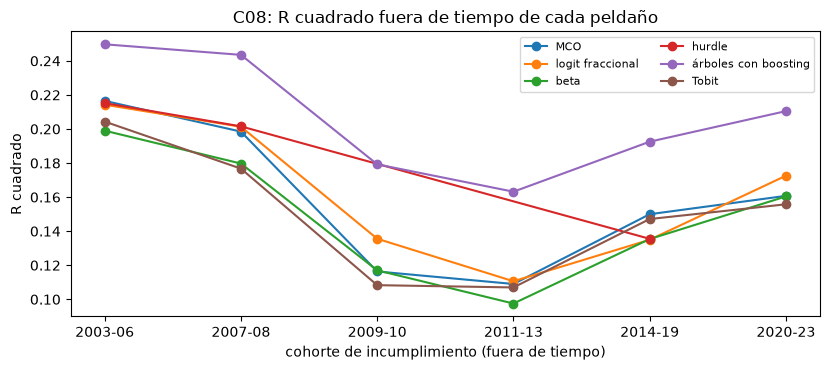

In [5]:
# Imprimir el rango del R cuadrado sobre todos los peldaños y cohortes y dibujar el R cuadrado de cada peldaño por cohorte
all_r2 = [r["r2"] for c in COHORTS for r in c08[c]["outputs"]["rung_comparison"]]
print(f"R cuadrado sobre {len(all_r2)} puntajes peldaño-cohorte: mínimo {min(all_r2):.4f} | máximo {max(all_r2):.4f} | dentro del intervalo de 4% a 43% de los estudios comparados: {0.04 <= min(all_r2) and max(all_r2) <= 0.43}")
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for rung_id in RUNG:
    xs = [i for i, c in enumerate(COHORTS) if any(r["rung_id"] == rung_id for r in c08[c]["outputs"]["rung_comparison"])]
    ys = [next(r["r2"] for r in c08[COHORTS[i]]["outputs"]["rung_comparison"] if r["rung_id"] == rung_id) for i in xs]
    ax.plot(xs, ys, marker="o", label=RUNG[rung_id])
ax.set_xticks(range(len(COHORTS)))
ax.set_xticklabels(COHORTS)
ax.set_xlabel("cohorte de incumplimiento (fuera de tiempo)")
ax.set_ylabel("R cuadrado")
ax.set_title("C08: R cuadrado fuera de tiempo de cada peldaño")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

### No lineal frente a lineal, y fraccional frente a MCO

Dos afirmaciones para comprobar sobre las cantidades derivadas del paso 1. Los métodos no paramétricos (no lineales) superan a los paramétricos cuando se controla el sobreajuste: aquí los árboles con boosting frente al logit fraccional, por ganancia de R cuadrado y por el peldaño con la mayor correlación de Spearman en cada cohorte. Y la regresión de respuesta fraccional tiene una pequeña ventaja sobre MCO: aquí la diferencia de R cuadrado y de RMSE entre ambos, que la celda cuenta sobre las cohortes. Una cautela para leerlas: los árboles con boosting tienen 200 árboles de profundidad 6 ajustados una vez con datos hasta el corte, y las cohortes son fuera de tiempo, así que el sobreajuste está controlado en el sentido del diseño de la prueba; el cuaderno no ajusta nada.

In [6]:
# Contar las cohortes donde se cumple cada afirmación, desde las cantidades derivadas en el paso 1
gains = [derived[c]["gain"] for c in COHORTS]
print(f"ganancia de R cuadrado de los árboles con boosting sobre el logit fraccional: mínimo {min(gains):+.4f} máximo {max(gains):+.4f} | positiva en {sum(g > 0 for g in gains)} de {len(COHORTS)} cohortes")
print("peldaño con la mayor correlación de Spearman:", {c: RUNG[derived[c]["best_sp"]] for c in COHORTS})
d_r2 = [derived[c]["d_r2"] for c in COHORTS]
d_rmse = [derived[c]["d_rmse"] for c in COHORTS]
print(f"logit fraccional menos MCO: R cuad. {['%+.4f' % x for x in d_r2]}")
print(f"  R cuadrado mayor en {sum(x > 0 for x in d_r2)} de {len(COHORTS)} | RMSE menor en {sum(x < 0 for x in d_rmse)} de {len(COHORTS)} | mayor diferencia absoluta: R cuad. {max(abs(x) for x in d_r2):.4f}, RMSE {max(abs(x) for x in d_rmse):.4f}")

ganancia de R cuadrado de los árboles con boosting sobre el logit fraccional: mínimo +0.0355 máximo +0.0576 | positiva en 6 de 6 cohortes
peldaño con la mayor correlación de Spearman: {'2003-06': 'árboles con boosting', '2007-08': 'árboles con boosting', '2009-10': 'árboles con boosting', '2011-13': 'árboles con boosting', '2014-19': 'árboles con boosting', '2020-23': 'árboles con boosting'}
logit fraccional menos MCO: R cuad. ['-0.0023', '+0.0029', '+0.0192', '+0.0016', '-0.0150', '+0.0118']
  R cuadrado mayor en 4 de 6 | RMSE menor en 4 de 6 | mayor diferencia absoluta: R cuad. 0.0192, RMSE 0.0034


### El modelo beta y su ajuste de extremos

Qi y Zhao encontraron que los modelos beta (y gaussiano inverso) son muy sensibles al número pequeño que se usa para mover los valores en 0 y 1 al interior del intervalo abierto. C08 informa esa sensibilidad para el peldaño beta en cada cohorte (`endpoint_sensitivity`). Para juzgar si la sensibilidad importa, la celda compara el rango de la predicción media sobre los tres ajustes con la diferencia de brecha de calibración entre el peldaño beta y el logit fraccional, que es el tamaño de la elección de familia de modelo. Cuando lo primero es mayor, la elección del ajuste mueve el nivel del modelo más que la elección entre esas dos familias.

In [7]:
# Comparar el rango de la predicción media del peldaño beta sobre epsilon con la diferencia de brecha de calibración entre beta y logit fraccional
print(f"{'cohorte':8s} {'rango sobre epsilon':>26s} {'|brecha(beta) - brecha(fraccional)|':>40s} {'epsilon lo mueve más':>28s}")
bigger = 0
for c in COHORTS:
    d = derived[c]
    bigger += d["eps_range"] > d["gap_diff"]
    print(f"{c:8s} {d['eps_range']:26.4f} {d['gap_diff']:40.4f} {d['eps_range'] > d['gap_diff']!s:>28s}")
print(f"cohortes donde el ajuste de extremos mueve el nivel más que la elección de familia: {bigger} de {len(COHORTS)}")

cohorte         rango sobre epsilon      |brecha(beta) - brecha(fraccional)|         epsilon lo mueve más
2003-06                      0.0057                                   0.0123                        False
2007-08                      0.0166                                   0.0145                         True
2009-10                      0.0234                                   0.0142                         True
2011-13                      0.0147                                   0.0067                         True
2014-19                      0.0016                                   0.0026                        False
2020-23                      0.0100                                   0.0011                         True
cohortes donde el ajuste de extremos mueve el nivel más que la elección de familia: 4 de 6


### Calibración y R cuadrado

La conclusión de la investigación es que la evaluación debe incluir la calibración y no solo el R cuadrado. Entre los peldaños de una misma cohorte, ¿un mayor R cuadrado va con una menor brecha de calibración? La celda imprime la correlación de rangos calculada en el paso 1 (negativa significa que sí) y si el peldaño con el mayor R cuadrado es también el de menor brecha absoluta en cada cohorte.

In [8]:
# Imprimir la correlación de rangos del R cuadrado con la brecha absoluta y si el mayor R cuadrado es también la menor brecha
same = 0
for c in COHORTS:
    rc = {r["rung_id"]: r for r in c08[c]["outputs"]["rung_comparison"]}
    top_r2 = max(rc, key=lambda k: rc[k]["r2"])
    top_gap = min(rc, key=lambda k: abs(rc[k]["calibration_gap"]))
    same += top_r2 == top_gap
    print(f"{c:8s} correlación de rangos {derived[c]['rho']:+.3f} | mayor R cuadrado: {RUNG[top_r2]:>24s} | menor brecha absoluta: {RUNG[top_gap]:>24s}")
print(f"el peldaño con mayor R cuadrado también tiene la menor brecha en {same} de {len(COHORTS)} cohortes")

2003-06  correlación de rangos -0.886 | mayor R cuadrado:     árboles con boosting | menor brecha absoluta:                      MCO
2007-08  correlación de rangos -0.771 | mayor R cuadrado:     árboles con boosting | menor brecha absoluta:     árboles con boosting
2009-10  correlación de rangos -0.800 | mayor R cuadrado:     árboles con boosting | menor brecha absoluta:         logit fraccional
2011-13  correlación de rangos +0.000 | mayor R cuadrado:     árboles con boosting | menor brecha absoluta:         logit fraccional
2014-19  correlación de rangos +0.371 | mayor R cuadrado:     árboles con boosting | menor brecha absoluta:                      MCO
2020-23  correlación de rangos -0.900 | mayor R cuadrado:     árboles con boosting | menor brecha absoluta:     árboles con boosting
el peldaño con mayor R cuadrado también tiene la menor brecha en 2 de 6 cohortes


### EAD: modelos de factor frente a un modelo directo

Para la exposición al incumplimiento, Tong et al. (2016) comparan modelos de EAD directos con variantes de CCF y un modelo de cambio de utilización sobre datos de tarjetas del Reino Unido y encuentran el modelo directo gamma ajustado en cero más exacto en calibración. Contraste no puede reproducir esa comparación, porque su modelo directo es un logit fraccional y no una mezcla gamma ajustada en cero (el docstring del motor lo dice). Lo que puede mostrar son las mismas tres familias sobre el generador C09 mediante el backtest del motor: la tabla del paso 2 y una figura de la métrica por nivel.

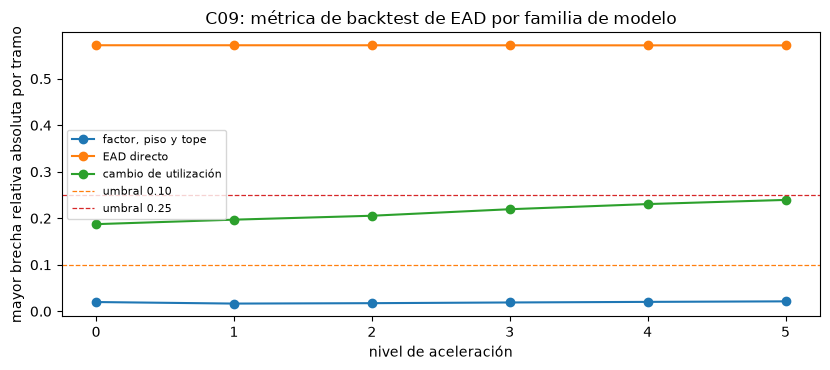

tramo con la mayor brecha del modelo directo, por nivel (utilización inferior-superior, brecha relativa): {0: (1.5, 4.0, -0.572), 1: (1.5, 4.0, -0.572), 2: (1.5, 4.0, -0.572), 3: (1.5, 4.0, -0.5719), 4: (1.5, 4.0, -0.5718), 5: (1.5, 4.0, -0.5718)}


In [9]:
# Dibujar la métrica de backtest de las tres familias de EAD en cada nivel de aceleración, con los umbrales verde y rojo
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for model_id, label in FAMILIES:
    if model_id != "ccf-fixed-horizon-none":
        ax.plot(range(6), [ead[i][model_id]["metric"] for i in range(6)], marker="o", label=label)
ax.axhline(0.10, color="tab:orange", linestyle="--", linewidth=0.9, label="umbral 0.10")
ax.axhline(0.25, color="tab:red", linestyle="--", linewidth=0.9, label="umbral 0.25")
ax.set_xlabel("nivel de aceleración")
ax.set_ylabel("mayor brecha relativa absoluta por tramo")
ax.set_title("C09: métrica de backtest de EAD por familia de modelo")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
worst = {i: max(ead[i]["direct-ead"]["extras"]["bands"], key=lambda b: abs(b["relative_gap"] or 0.0)) for i in range(6)}
print("tramo con la mayor brecha del modelo directo, por nivel (utilización inferior-superior, brecha relativa):", {i: (b["lower"], b["upper"], round(b["relative_gap"], 4)) for i, b in worst.items()})

## Resultados

- **El R cuadrado es bajo y está dentro del rango de los estudios comparados.** Sobre los 33 puntajes peldaño-cohorte de C08 el R cuadrado va de 0,0975 a 0,2497, dentro del intervalo de 4% a 43% que informan los estudios comparados.
- **Aquí lo no lineal supera a lo lineal.** Los árboles con boosting ganan de 0,0355 a 0,0576 de R cuadrado sobre el logit fraccional en las seis cohortes, y tienen la mayor correlación de Spearman en las seis. Esto concuerda con la afirmación de los estudios comparados en estos datos, con la salvedad de que el objetivo es un proxy.
- **La ventaja del logit fraccional sobre MCO es pequeña y mixta.** Tiene el mayor R cuadrado en 4 de 6 cohortes y el menor RMSE en 4 de 6, y la mayor diferencia es de 0,0192 de R cuadrado y 0,0034 de RMSE, frente a la ganancia de 0,0355 a 0,0576 de los árboles con boosting.
- **El ajuste de extremos del peldaño beta importa.** El rango de su predicción media sobre los tres ajustes va de 0,0016 a 0,0234, y supera la diferencia de brecha de calibración entre el peldaño beta y el logit fraccional en 4 de las 6 cohortes: en ellas, la elección del número pequeño mueve el nivel más que la elección entre esas dos familias.
- **El R cuadrado y la calibración van juntos solo en parte.** Entre los peldaños de una cohorte, la correlación de rangos entre el R cuadrado y la brecha absoluta está entre -0,771 y -0,900 en cuatro cohortes (un mayor R cuadrado va con una menor brecha), es 0,000 en 2011-13 y +0,371 en 2014-19; el peldaño con el mayor R cuadrado tiene la menor brecha absoluta en solo 2 de las 6 cohortes (2007-08 y 2020-23). La calibración debe leerse por sí misma.
- **En EAD, los modelos de factor pasan y el logit fraccional directo falla.** Los modelos de factor están en verde en los seis niveles (0,0166 a 0,0271), el modelo de cambio de utilización está en ámbar y crece con el nivel (0,1874 a 0,2395), y el modelo directo está en rojo en todos los niveles (0,5718 a 0,5720) en el mismo tramo, de 1,5 a 4,0 veces el límite, habiendo recortado entre 5.958 y 14.778 líneas. El motor, vuelto a correr sobre los totales por tramo del nivel 4, da la métrica y la luz versionadas para tres modelos.
- **Lo que no se reproduce.** El modelo directo gamma ajustado en cero de Tong et al. (2016) no está en el motor, así que el hallazgo de que calibra mejor que los modelos de factor no se confirma ni se contradice; tampoco están implementados los modelos beta inflada en cero o uno, condicionados al ciclo macro ni de supervivencia.

Lo que estas comprobaciones no muestran: usan un proxy de castigos con un sesgo declarado y un generador sintético cuya verdad está definida a doce meses, así que dicen cómo se comportan los modelos en estos datos y no los ordenan para ningún banco. Las afirmaciones comparadas son las de la investigación tal como las registró desde resúmenes, no una revisión de los artículos completos.

## Resumen

- La literatura comparada de LGD encuentra R cuadrado bajo en todas partes, una ventaja de los métodos no lineales, una pequeña de la respuesta fraccional sobre MCO, y una fuerte sensibilidad del modelo beta a su ajuste de extremos; para la EAD compara modelos directos con modelos de factor y de cambio de utilización. Contraste implementa MCO, logit fraccional, beta, un hurdle logit-fraccional y Tobit para la LGD, árboles con boosting en su pipeline, y los modelos de factor, directo (logit fraccional) y de cambio de utilización para la EAD; no implementa los modelos gamma ajustado en cero, beta inflada, condicionados al ciclo macro ni de supervivencia.
- En las seis cohortes de C08 el R cuadrado queda dentro del rango de los estudios comparados, los árboles con boosting tienen el mayor R cuadrado y la mayor correlación de Spearman en cada cohorte, la ventaja del logit fraccional sobre MCO es pequeña y mixta, y en cuatro de las seis cohortes el nivel del peldaño beta se mueve más con su ajuste de extremos que con la elección entre él y el logit fraccional.
- El peldaño con el mayor R cuadrado es el mejor calibrado solo en algunas cohortes, así que la calibración debe juzgarse junto al R cuadrado.
- En el generador C09 los modelos de factor pasan el backtest del motor en todos los niveles, el modelo de cambio de utilización está en ámbar, y el logit fraccional directo falla en el mismo tramo en todos los niveles. Esto no reproduce a Tong et al. (2016), cuyo modelo directo es otro.
- Todo esto trata de un proxy de castigos y un generador sintético, así que es una afirmación sobre los modelos en estos datos.

**Qué probar a continuación.** Lee el `endpoint_sensitivity` versionado y la calibración por tramo de una cohorte junto al R cuadrado de cada peldaño y escribe qué peldaño llevarías a un comité de modelos, y qué evidencia pedirías todavía. Este tema no tiene cuaderno de nivel 4: ningún reclamo del SDD descansa aún en los casos de LGD y EAD.

## Referencias

- Loterman, G., Brown, I., Martens, D., Mues, C. y Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1):161-170. https://doi.org/10.1016/j.ijforecast.2011.01.006
- Qi, M. y Zhao, X. (2011), Comparison of modeling methods for loss given default, Journal of Banking and Finance 35(11):2842-2855. https://doi.org/10.1016/j.jbankfin.2011.03.011
- Leow, M. y Mues, C. (2012), Predicting loss given default (LGD) for residential mortgage loans: a two-stage model and empirical evidence for UK bank data, International Journal of Forecasting 28(1):183-195. https://doi.org/10.1016/j.ijforecast.2011.01.010
- Tong, E. N. C., Mues, C. y Thomas, L. (2013), A zero-adjusted gamma model for mortgage loan loss given default, International Journal of Forecasting 29(4):548-562. https://doi.org/10.1016/j.ijforecast.2013.03.003
- Ospina, R. y Ferrari, S. L. P. (2012), A general class of zero-or-one inflated beta regression models, Computational Statistics and Data Analysis 56(6):1609-1623. https://doi.org/10.1016/j.csda.2011.10.005
- Bellotti, T. y Crook, J. (2012), Loss given default models incorporating macroeconomic variables for credit cards, International Journal of Forecasting 28(1):171-182. https://doi.org/10.1016/j.ijforecast.2010.08.005
- Tong, E. N. C., Mues, C., Brown, I. y Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3):910-920. https://doi.org/10.1016/j.ejor.2016.01.054
- Leow, M. y Crook, J. (2013), Estimation of credit card exposure at default (EAD), documento de trabajo, University of Edinburgh Credit Research Centre (según el dosier de investigación; leído en las pp. 1 a 5).
- BCBS, Basel Framework, CRE32. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- El dosier de investigación de este producto sobre modelos de riesgo de crédito (secciones de LGD y de EAD y CCF), que registra los hallazgos de arriba a partir de resúmenes y búsquedas, y la documentación del motor de `fit_direct_ead` (versión 0.8.1).
- Este repositorio: `docs/design/SDD.md` (casos C08 y C09) y `data/derived/C08/`, `data/derived/C09/`.